In [1]:
import math
from collections.abc import Callable
from dataclasses import dataclass

import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt


l = math.pi / 2
T = 2

a = 1
b = 2
c = -3
mu = 2

N = 100
sigma = 0.5

**Вариант 7**

$
\begin{cases}
\dfrac{\partial^2 u}{\partial t^2} + 2\dfrac{\partial u}{\partial t} = \dfrac{\partial^2 u}{\partial x^2} + 2\dfrac{\partial u}{\partial x} - 3u, \quad 0 < x < \dfrac{\pi}{2},\ t > 0, \\
u(0, t) = e^{-t}\cos 2t, \\
u\left(\dfrac{\pi}{2}, t\right) = 0, \\
u(x, 0) = e^{-x}\cos x, \\
u_t(x, 0) = -e^{-x}\cos x,
\end{cases}
\qquad
U(x, t) = e^{-t-x}\cos x\cos 2t
$

Общая постановка - третья начально-краевая задача, дополненная слагаемым с первой производной по времени:

$
\dfrac{\partial^2 u}{\partial t^2} + \mu\dfrac{\partial u}{\partial t} = a^2\dfrac{\partial^2 u}{\partial x^2} + b\dfrac{\partial u}{\partial x} + cu + f(x, t), \qquad
\alpha u_x(0,t) + \beta u(0,t) = \varphi_0(t), \qquad
\gamma u_x(l,t) + \delta u(l,t) = \varphi_l(t),
$

$
u(x, 0) = \psi_1(x), \qquad \dfrac{\partial u}{\partial t}(x, 0) = \psi_2(x),
$

$a = 1$, $b = 2$, $c = -3$, $\mu = 2$, $f = 0$, $l = \pi/2$, $\alpha = 0$, $\beta = 1$, $\varphi_0(t) = e^{-t}\cos 2t$, $\gamma = 0$, $\delta = 1$, $\varphi_l(t) = 0$, $\psi_1(x) = e^{-x}\cos x$, $\psi_2(x) = -e^{-x}\cos x$.

Граничные условия первого рода - частный случай условий третьего рода при $\alpha = \gamma = 0$. Все схемы выписываем для общей постановки. В варианте 7 граничные условия не содержат производных, поэтому три способа их аппроксимации совпадают; чтобы сравнить их, решаем ту же задачу с условиями второго рода, построенными по $U(x, t)$.

Проверим символьно, что $U(x, t)$ удовлетворяет уравнению, граничным и начальным условиям, и получим производные $\psi_1'$, $\psi_1''$, которые понадобятся для аппроксимации второго начального условия:

In [2]:
xs, ts = sp.symbols('x t')

U_sym = sp.exp(-ts - xs) * sp.cos(xs) * sp.cos(2 * ts)
psi_1_sym = sp.exp(-xs) * sp.cos(xs)
psi_2_sym = -sp.exp(-xs) * sp.cos(xs)

residual = U_sym.diff(ts, 2) + mu * U_sym.diff(ts) - (a**2 * U_sym.diff(xs, 2) + b * U_sym.diff(xs) + c * U_sym)

print('U(0, t)          =', U_sym.subs(xs, 0))
print('U(pi/2, t)       =', sp.simplify(U_sym.subs(xs, sp.pi / 2)))
print('U(x, 0) - psi_1  =', sp.simplify(U_sym.subs(ts, 0) - psi_1_sym))
print('U_t(x, 0) - psi_2 =', sp.simplify(U_sym.diff(ts).subs(ts, 0) - psi_2_sym))
print("psi_1'           =", psi_1_sym.diff(xs))
print("psi_1''          =", sp.simplify(psi_1_sym.diff(xs, 2)))

U(0, t)          = exp(-t)*cos(2*t)
U(pi/2, t)       = 0
U(x, 0) - psi_1  = 0
U_t(x, 0) - psi_2 = 0
psi_1'           = -exp(-x)*sin(x) - exp(-x)*cos(x)
psi_1''          = 2*exp(-x)*sin(x)


In [3]:
u_exact = sp.lambdify((xs, ts), U_sym, 'numpy')
psi_1 = sp.lambdify(xs, psi_1_sym, 'numpy')
psi_2 = sp.lambdify(xs, psi_2_sym, 'numpy')
dpsi_1 = sp.lambdify(xs, psi_1_sym.diff(xs), 'numpy')
d2psi_1 = sp.lambdify(xs, psi_1_sym.diff(xs, 2), 'numpy')
f = lambda x, t: 0 * x * t

@dataclass(frozen=True)
class Conditions:
    # alpha * u_x(0, t) + beta * u(0, t) = phi_0(t)
    alpha: float
    beta: float
    phi_0: Callable
    # gamma * u_x(l, t) + delta * u(l, t) = phi_l(t)
    gamma: float
    delta: float
    phi_l: Callable

dirichlet = Conditions(
    alpha=0, beta=1, phi_0=lambda t: np.exp(-t) * np.cos(2 * t),
    gamma=0, delta=1, phi_l=lambda t: 0 * t,
)

## Конечно-разностная сетка

Нанесём на область $0 \le x \le l$, $0 \le t \le T$ сетку:

$
\omega_{h\tau} = \{x_j = jh,\ j = \overline{0, N};\ t^k = k\tau,\ k = \overline{0, K}\}, \qquad h = \dfrac{l}{N}, \quad \tau = \dfrac{T}{K}.
$

В отличие от параболического уравнения схемы для волнового уравнения **трёхслойные**: значения на верхнем слое $t^{k+1}$ находятся по двум нижним слоям $t^k$ и $t^{k-1}$. Сеточный параметр $\sigma = \dfrac{a^2\tau^2}{h^2}$; по заданному $\sigma$ число шагов по времени $K = \left\lceil \dfrac{aT}{\sqrt{\sigma}\,h} \right\rceil$.

Погрешность на слое $t^k$: $\varepsilon^k = \max_j |u_j^k - U(x_j, t^k)|$.

Граничным условиям на каждом шаге нужны время верхнего слоя $t^{k+1}$, шаги $h$, $\tau$ и решение на двух нижних слоях $u^k$, $u^{k-1}$ (последние - только двухточечной аппроксимации второго порядка). Передаём их одним объектом класса `TimeStep` с полями `t_next`, `h`, `tau`, `u_curr`, `u_prev`.

In [4]:
def make_grid(N, K):
    x = np.linspace(0, l, N + 1)
    t = np.linspace(0, T, K + 1)

    return x, t, l / N, T / K


def steps_for_sigma(N, sigma):
    h = l / N
    return math.ceil(T * a / (math.sqrt(sigma) * h))


def error(x, t, u):
    return np.max(np.abs(u - u_exact(x[None, :], t[:, None])), axis=1)


@dataclass(frozen=True)
class TimeStep:
    t_next: float
    h: float
    tau: float
    u_curr: np.ndarray
    u_prev: np.ndarray

# 1. Явная схема «крест»

## Внутренние узлы

На шаблоне «крест» аппроксимируем все производные центральными разностями второго порядка:

$
\left.\dfrac{\partial^2 u}{\partial t^2}\right|_j^k = \dfrac{u_j^{k+1} - 2u_j^k + u_j^{k-1}}{\tau^2} + O(\tau^2), \qquad
\left.\dfrac{\partial^2 u}{\partial x^2}\right|_j^k = \dfrac{u_{j+1}^k - 2u_j^k + u_{j-1}^k}{h^2} + O(h^2), \qquad
\left.\dfrac{\partial u}{\partial x}\right|_j^k = \dfrac{u_{j+1}^k - u_{j-1}^k}{2h} + O(h^2).
$

Аппроксимируем слагаемое $\mu\,\partial u / \partial t$ центральной разностью, только по времени (узлы $k \pm 1$ есть на шаблоне «крест»):

$
\left.\dfrac{\partial u}{\partial t}\right|_j^k = \dfrac{u_j^{k+1} - u_j^{k-1}}{2\tau} + O(\tau^2).
$

Получаем явную схему:

$
\dfrac{u_j^{k+1} - 2u_j^k + u_j^{k-1}}{\tau^2} + \mu\dfrac{u_j^{k+1} - u_j^{k-1}}{2\tau} = a^2\dfrac{u_{j+1}^k - 2u_j^k + u_{j-1}^k}{h^2} + b\dfrac{u_{j+1}^k - u_{j-1}^k}{2h} + cu_j^k + f_j^k + O(\tau^2 + h^2), \qquad j = \overline{1, N-1}, \quad k = 1, 2, \dots
$

Умножим на $\tau^2$ и выразим единственное неизвестное $u_j^{k+1}$:

$
\left(1 + \dfrac{\mu\tau}{2}\right)u_j^{k+1} = \left(\sigma + b\dfrac{\tau^2}{2h}\right)u_{j+1}^k + \left(2 - 2\sigma + c\tau^2\right)u_j^k + \left(\sigma - b\dfrac{\tau^2}{2h}\right)u_{j-1}^k - \left(1 - \dfrac{\mu\tau}{2}\right)u_j^{k-1} + \tau^2 f_j^k, \qquad \sigma = \dfrac{a^2\tau^2}{h^2}.
$

При $\mu = 0$ это в точности формула перехода на новый слой. Схема условно устойчива: $\sigma < 1$, то есть $\tau < h / a$. Ограничение здесь мягче, чем у явной схемы для параболического уравнения: шаг по времени уменьшается пропорционально $h$, а не $h^2$.

## Начальные условия

Для первого шага трёхслойной схемы нужны значения на двух слоях $t^0$ и $t^1$. На нулевом слое они известны точно:

$
u_j^0 = \psi_1(x_j), \qquad j = \overline{0, N}.
$

### Аппроксимация второго начального условия с первым порядком

Заменим производную по времени разностью вперёд:

$
\dfrac{u_j^1 - u_j^0}{\tau} = \psi_2(x_j) \quad\Rightarrow\quad u_j^1 = \psi_1(x_j) + \psi_2(x_j)\,\tau.
$

Локальная погрешность на слое $t^1$ - $O(\tau^2)$, но это то же самое, что погрешность $O(\tau)$ в начальной скорости. Волновое уравнение «помнит» начальную скорость, поэтому такая ошибка не затухает со временем и итоговая погрешность решения будет $O(\tau)$, даже если сама схема имеет второй порядок.

### Аппроксимация второго начального условия со вторым порядком

Разложим $u_j^1$ в ряд Тейлора на точном решении в окрестности $t = 0$:

$
u_j^1 = u(x_j, 0 + \tau) = u_j^0 + \left.\dfrac{\partial u}{\partial t}\right|_j^0\tau + \left.\dfrac{\partial^2 u}{\partial t^2}\right|_j^0\dfrac{\tau^2}{2} + O(\tau^3).
$

Вторую производную по времени выразим из исходного уравнения. Слагаемое $\mu\,\partial u / \partial t$, которое при $t = 0$ равно $\mu\psi_2(x_j)$:

$
\left.\dfrac{\partial^2 u}{\partial t^2}\right|_j^0 = a^2\left.\dfrac{\partial^2 u}{\partial x^2}\right|_j^0 + b\left.\dfrac{\partial u}{\partial x}\right|_j^0 + cu_j^0 + f_j^0 - \mu\left.\dfrac{\partial u}{\partial t}\right|_j^0
= a^2\psi_1''(x_j) + b\psi_1'(x_j) + c\psi_1(x_j) + f(x_j, 0) - \mu\psi_2(x_j).
$

Окончательно:

$
u_j^1 = \psi_1(x_j) + \psi_2(x_j)\,\tau + \left(a^2\psi_1''(x_j) + b\psi_1'(x_j) + c\psi_1(x_j) + f(x_j, 0) - \mu\psi_2(x_j)\right)\dfrac{\tau^2}{2},
$

где для варианта 7 $\psi_1'(x) = -e^{-x}(\cos x + \sin x)$, $\psi_1''(x) = 2e^{-x}\sin x$.

Начальные условия одинаковы для явной и неявной схем.

In [5]:
def initial_first_order(x, tau):
    return psi_1(x) + psi_2(x) * tau


def initial_second_order(x, tau):
    u_tt = a * a * d2psi_1(x) + b * dpsi_1(x) + c * psi_1(x) + f(x, 0) - mu * psi_2(x)
    return psi_1(x) + psi_2(x) * tau + u_tt * tau * tau / 2


initials = {
    'O(τ)': initial_first_order,
    'O(τ²)': initial_second_order,
}

Формулы для $u_j^1$ дают значения и в граничных узлах $j = 0$, $j = N$. Если на границе задано условие первого рода ($\alpha = 0$ или $\gamma = 0$), значение на слое $t^1$ известно из него точно, $u_0^1 = \varphi_0(t^1)/\beta$, $u_N^1 = \varphi_l(t^1)/\delta$, - его и берём. Для условия с производной оставляем значение из формулы для $u_j^1$: у него та же точность, что во внутренних узлах первого слоя. Двухточечную аппроксимацию второго порядка на первом слое применить нельзя: ей нужен нижний слой $u^{k-1}$, то есть $u^{-1}$, которого нет.

In [6]:
def set_first_layer_boundary(u_1, t_1, cond):
    if cond.alpha == 0:
        u_1[0] = cond.phi_0(t_1) / cond.beta
    if cond.gamma == 0:
        u_1[-1] = cond.phi_l(t_1) / cond.delta

## Граничные узлы

Формула для внутренних узлов даёт только $u_1^{k+1}, \dots, u_{N-1}^{k+1}$. Краевые условия аппроксимируются так же, как для уравнения параболического типа - на верхнем слое $t^{k+1}$. Каждая из трёх аппроксимаций даёт по одному уравнению на границе, содержащему не более трёх неизвестных:

$
b_0 u_0^{k+1} + c_0 u_1^{k+1} + e_0 u_2^{k+1} = d_0, \qquad
e_N u_{N-2}^{k+1} + a_N u_{N-1}^{k+1} + b_N u_N^{k+1} = d_N.
$

Функции ниже возвращают коэффициенты этих уравнений. Явная схема просто выражает из них $u_0^{k+1}$ и $u_N^{k+1}$, а неявная ставит их первой и последней строками СЛАУ, поэтому одни и те же функции годятся для обеих схем.

### Двухточечная аппроксимация с первым порядком

Заменим производные направленными разностями:

$
\left.\dfrac{\partial u}{\partial x}\right|_{j=0}^{k+1} = \dfrac{u_1^{k+1} - u_0^{k+1}}{h} + O(h), \qquad
\left.\dfrac{\partial u}{\partial x}\right|_{j=N}^{k+1} = \dfrac{u_N^{k+1} - u_{N-1}^{k+1}}{h} + O(h).
$

Граничные условия принимают вид

$
\alpha\dfrac{u_1^{k+1} - u_0^{k+1}}{h} + \beta u_0^{k+1} = \varphi_0(t^{k+1}), \qquad
\gamma\dfrac{u_N^{k+1} - u_{N-1}^{k+1}}{h} + \delta u_N^{k+1} = \varphi_l(t^{k+1}),
$

$
b_0 = \beta - \dfrac{\alpha}{h}, \quad c_0 = \dfrac{\alpha}{h}, \quad e_0 = 0, \quad d_0 = \varphi_0(t^{k+1}); \qquad
e_N = 0, \quad a_N = -\dfrac{\gamma}{h}, \quad b_N = \delta + \dfrac{\gamma}{h}, \quad d_N = \varphi_l(t^{k+1}).
$

In [7]:
def boundary_two_point_first_order(cond, time_step):
    t_next, h = time_step.t_next, time_step.h

    left = (cond.beta - cond.alpha / h, cond.alpha / h, 0, cond.phi_0(t_next))
    right = (0, -cond.gamma / h, cond.delta + cond.gamma / h, cond.phi_l(t_next))

    return left, right

### Трёхточечная аппроксимация со вторым порядком

Используем формулы численного дифференцирования второго порядка:

$
\dfrac{\partial u}{\partial x}(0, t^{k+1}) = \dfrac{-3u_0^{k+1} + 4u_1^{k+1} - u_2^{k+1}}{2h} + O(h^2), \qquad
\dfrac{\partial u}{\partial x}(l, t^{k+1}) = \dfrac{u_{N-2}^{k+1} - 4u_{N-1}^{k+1} + 3u_N^{k+1}}{2h} + O(h^2).
$

Подставляя их в граничные условия, получаем уравнения с тремя неизвестными:

$
b_0 = \beta - \dfrac{3\alpha}{2h}, \quad c_0 = \dfrac{2\alpha}{h}, \quad e_0 = -\dfrac{\alpha}{2h}, \quad d_0 = \varphi_0(t^{k+1}); \qquad
e_N = \dfrac{\gamma}{2h}, \quad a_N = -\dfrac{2\gamma}{h}, \quad b_N = \delta + \dfrac{3\gamma}{2h}, \quad d_N = \varphi_l(t^{k+1}).
$

In [8]:
def boundary_three_point_second_order(cond, time_step):
    t_next, h = time_step.t_next, time_step.h

    left = (cond.beta - 3 * cond.alpha / (2 * h), 2 * cond.alpha / h, -cond.alpha / (2 * h), cond.phi_0(t_next))
    right = (cond.gamma / (2 * h), -2 * cond.gamma / h, cond.delta + 3 * cond.gamma / (2 * h), cond.phi_l(t_next))

    return left, right

### Двухточечная аппроксимация со вторым порядком

Повысим порядок, не добавляя узлов. Разложим $u_1^{k+1}$ и $u_{N-1}^{k+1}$ в ряд Тейлора в окрестности граничных узлов:

$
u_1^{k+1} = u_0^{k+1} + \left.\dfrac{\partial u}{\partial x}\right|_0^{k+1} h + \left.\dfrac{\partial^2 u}{\partial x^2}\right|_0^{k+1}\dfrac{h^2}{2} + O(h^3), \qquad
u_{N-1}^{k+1} = u_N^{k+1} - \left.\dfrac{\partial u}{\partial x}\right|_N^{k+1} h + \left.\dfrac{\partial^2 u}{\partial x^2}\right|_N^{k+1}\dfrac{h^2}{2} + O(h^3).
$

Вторую производную по $x$ выразим из самого уравнения:

$
\dfrac{\partial^2 u}{\partial x^2} = \dfrac{1}{a^2}\left(\dfrac{\partial^2 u}{\partial t^2} + \mu\dfrac{\partial u}{\partial t} - b\dfrac{\partial u}{\partial x} - cu - f\right).
$

Подставив и собрав слагаемые с $\partial u / \partial x$, получим первую производную в граничных узлах с порядком $O(h^2)$:

$
\left.\dfrac{\partial u}{\partial x}\right|_0^{k+1} = \dfrac{1}{2a^2 - bh}\left[\dfrac{2a^2}{h}(u_1^{k+1} - u_0^{k+1}) - h\left(\dfrac{\partial^2 u}{\partial t^2} + \mu\dfrac{\partial u}{\partial t} - cu - f\right)_0^{k+1}\right],
$

$
\left.\dfrac{\partial u}{\partial x}\right|_N^{k+1} = \dfrac{1}{2a^2 + bh}\left[\dfrac{2a^2}{h}(u_N^{k+1} - u_{N-1}^{k+1}) + h\left(\dfrac{\partial^2 u}{\partial t^2} + \mu\dfrac{\partial u}{\partial t} - cu - f\right)_N^{k+1}\right].
$

Производные по времени в граничных узлах заменим теми же разностями, что и во внутренних узлах:

$
\left(\dfrac{\partial^2 u}{\partial t^2} + \mu\dfrac{\partial u}{\partial t}\right)_j^{k+1} \approx \dfrac{u_j^{k+1} - 2u_j^k + u_j^{k-1}}{\tau^2} + \mu\dfrac{u_j^{k+1} - u_j^{k-1}}{2\tau} = P u_j^{k+1} - R_j,
\qquad P = \dfrac{1}{\tau^2} + \dfrac{\mu}{2\tau}, \quad R_j = \dfrac{2u_j^k - u_j^{k-1}}{\tau^2} + \dfrac{\mu}{2\tau}u_j^{k-1}.
$

Эти разности центрированы в $t^k$, а используются на слое $t^{k+1}$, поэтому их погрешность $O(\tau)$. Они входят с множителем $h$, так что погрешность граничного условия $O(h^2 + h\tau)$. На сетках, которые мы используем ($\tau \sim h$ и $\tau \sim h^2$), это $O(h^2)$ или лучше.

Подставим это в граничные условия и умножим на $2a^2 \mp bh$. На $\alpha$ и $\gamma$ не делим, чтобы формулы оставались верными и при $\alpha = 0$ или $\gamma = 0$:

$
b_0 = \alpha\left(-\dfrac{2a^2}{h} - hP + ch\right) + \beta(2a^2 - bh), \quad c_0 = \dfrac{2a^2\alpha}{h}, \quad e_0 = 0, \quad
d_0 = \varphi_0(t^{k+1})(2a^2 - bh) - \alpha h\left(R_0 + f_0^{k+1}\right);
$

$
e_N = 0, \quad a_N = -\dfrac{2a^2\gamma}{h}, \quad b_N = \gamma\left(\dfrac{2a^2}{h} + hP - ch\right) + \delta(2a^2 + bh), \quad
d_N = \varphi_l(t^{k+1})(2a^2 + bh) + \gamma h\left(R_N + f_N^{k+1}\right).
$

Для условий первого рода ($\alpha = \gamma = 0$, $\beta = \delta = 1$) все три аппроксимации вырождаются в точные равенства $u_0^{k+1} = \varphi_0(t^{k+1})$, $u_N^{k+1} = \varphi_l(t^{k+1})$, поэтому в варианте 7 они дают одинаковый результат.

In [9]:
def boundary_two_point_second_order(cond, time_step):
    t_next, h, tau = time_step.t_next, time_step.h, time_step.tau
    u_curr, u_prev = time_step.u_curr, time_step.u_prev

    P = 1 / tau**2 + mu / (2 * tau)
    R_0 = (2 * u_curr[0] - u_prev[0]) / tau**2 + mu / (2 * tau) * u_prev[0]
    R_N = (2 * u_curr[-1] - u_prev[-1]) / tau**2 + mu / (2 * tau) * u_prev[-1]

    left = (
        cond.alpha * (-2 * a * a / h - h * P + c * h) + cond.beta * (2 * a * a - b * h),
        2 * a * a * cond.alpha / h,
        0,
        cond.phi_0(t_next) * (2 * a * a - b * h) - cond.alpha * h * (R_0 + f(0, t_next)),
    )
    right = (
        0,
        -2 * a * a * cond.gamma / h,
        cond.gamma * (2 * a * a / h + h * P - c * h) + cond.delta * (2 * a * a + b * h),
        cond.phi_l(t_next) * (2 * a * a + b * h) + cond.gamma * h * (R_N + f(l, t_next)),
    )

    return left, right


boundaries = {
    '2 точки, O(h)': boundary_two_point_first_order,
    '3 точки, O(h²)': boundary_three_point_second_order,
    '2 точки, O(h²)': boundary_two_point_second_order,
}

## Алгоритм явной схемы

Слои $u^0$, $u^1$ берём из начальных условий (граничные значения первого слоя - как описано выше). Далее на каждом шаге сначала считаем все внутренние узлы, затем из граничных уравнений находим

$
u_0^{k+1} = \dfrac{d_0 - c_0 u_1^{k+1} - e_0 u_2^{k+1}}{b_0}, \qquad u_N^{k+1} = \dfrac{d_N - a_N u_{N-1}^{k+1} - e_N u_{N-2}^{k+1}}{b_N}.
$

Решение хранится в матрице `u[k, j]`$= u_j^k$.

In [10]:
def explicit_scheme(initial, boundary, N, K, cond=dirichlet):
    x, t, h, tau = make_grid(N, K)
    sigma = a * a * tau * tau / (h * h)

    u = np.zeros((K + 1, N + 1), dtype=np.float64)
    u[0] = psi_1(x)
    u[1] = initial(x, tau)
    set_first_layer_boundary(u[1], t[1], cond)

    for k in range(1, K):
        u[k + 1, 1:-1] = (
            (sigma + b * tau * tau / (2 * h)) * u[k, 2:]
            + (2 - 2 * sigma + c * tau * tau) * u[k, 1:-1]
            + (sigma - b * tau * tau / (2 * h)) * u[k, :-2]
            - (1 - mu * tau / 2) * u[k - 1, 1:-1]
            + tau * tau * f(x[1:-1], t[k])
        ) / (1 + mu * tau / 2)

        (b_0, c_0, e_0, d_0), (e_N, a_N, b_N, d_N) = boundary(cond, TimeStep(t[k + 1], h, tau, u[k], u[k - 1]))

        u[k + 1, 0] = (d_0 - c_0 * u[k + 1, 1] - e_0 * u[k + 1, 2]) / b_0
        u[k + 1, -1] = (d_N - a_N * u[k + 1, -2] - e_N * u[k + 1, -3]) / b_N

    return x, t, u


def run_all(scheme, N, K, cond=dirichlet):
    return {
        (initial_name, boundary_name): scheme(initial, boundary, N, K, cond)
        for initial_name, initial in initials.items()
        for boundary_name, boundary in boundaries.items()
    }

## Результаты явной схемы

Возьмём $N = 100$ и $\sigma = 0.5 < 1$. Решаем для обоих способов аппроксимации второго начального условия и всех трёх аппроксимаций граничных условий.

In [11]:
K = steps_for_sigma(N, sigma)
x, t, h, tau = make_grid(N, K)
print(f'h = {h:.5f}, tau = {tau:.5f}, K = {K}, sigma = {a * a * tau * tau / (h * h):.4f}')

explicit_results = run_all(explicit_scheme, N, K)

h = 0.01571, tau = 0.01105, K = 181, sigma = 0.4948


Как и ожидалось, для условий первого рода аппроксимации граничных условий дают одно и то же решение:

In [12]:
def boundaries_coincide(results):
    first = list(boundaries)[0]
    return all(
        np.allclose(results[(initial_name, boundary_name)][2], results[(initial_name, first)][2], rtol=0, atol=1e-12)
        for initial_name, boundary_name in results
    )


boundaries_coincide(explicit_results)

True

Функции для графиков и таблиц, которые будем использовать для всех схем. Для каждого решения строим четыре графика:

- решение $u(x, t)$ от $x$ в моменты $t = 0.5, 1, 2$;
- решение $u(x, t)$ от $t$ во внутренних точках $x = l/4, l/2, 3l/4$;
- погрешность $\varepsilon(t) = \max_j |u_j^k - U(x_j, t^k)|$ от $t$;
- поточечную погрешность $|u_j^k - U(x_j, t^k)|$ от $x$ в те же моменты $t = 0.5, 1, 2$.

Сплошные линии - численное решение, красный пунктир - аналитическое.

In [13]:
time_moments = [0.25, 0.5, 1, 1.5, 2]


plot_times = [0.5, 1, 2]


def layer(t_n, moment):
    return int(round(moment / (t_n[1] - t_n[0])))


def plot_exact(ax, x, curves):
    for i, curve in enumerate(curves):
        ax.plot(x, curve, color='red', linestyle='--', linewidth=1.5, label='U' if i == 0 else None)
    ax.legend()


def plot_results(results, title):
    for name, (x_n, t_n, u_n) in results.items():
        u_exact_n = u_exact(x_n[None, :], t_n[:, None])
        layers = [layer(t_n, moment) for moment in plot_times]
        points = [(len(x_n) - 1) // 4, (len(x_n) - 1) // 2, 3 * (len(x_n) - 1) // 4]
        colors = sns.color_palette()

        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle(f'{title}, {name}')

        for k, moment, color in zip(layers, plot_times, colors):
            sns.lineplot(x=x_n, y=u_n[k], label=f't = {moment}', color=color, linewidth=3, ax=axes[0, 0])
            sns.lineplot(x=x_n, y=np.abs(u_n[k] - u_exact_n[k]), label=f't = {moment}', color=color, ax=axes[1, 1])

        for j, color in zip(points, colors):
            sns.lineplot(x=t_n, y=u_n[:, j], label=f'x = {x_n[j]:.3f}', color=color, linewidth=3, ax=axes[0, 1])

        plot_exact(axes[0, 0], x_n, [u_exact_n[k] for k in layers])
        plot_exact(axes[0, 1], t_n, [u_exact_n[:, j] for j in points])

        sns.lineplot(x=t_n, y=error(x_n, t_n, u_n), ax=axes[1, 0])

        axes[0, 0].set(title='решение от x', xlabel='x', ylabel='u')
        axes[0, 1].set(title='решение от t', xlabel='t', ylabel='u')
        axes[1, 0].set(title='погрешность от t', xlabel='t', ylabel='max |u - U|')
        axes[1, 1].set(title='погрешность от x', xlabel='x', ylabel='|u - U|')


def error_table(results, index_names=('начальное условие', 'граничные условия')):
    rows = {}

    for name, (x_n, t_n, u_n) in results.items():
        eps_n = error(x_n, t_n, u_n)
        rows[name] = {f't = {moment}': eps_n[layer(t_n, moment)] for moment in time_moments}

    table = pd.DataFrame(rows).T
    table.index.names = index_names
    return table


def by_initial(results, boundary_name='2 точки, O(h)'):
    return {f'2-е НУ с {initial_name}': results[(initial_name, boundary_name)] for initial_name in initials}

Так как аппроксимации граничных условий совпадают, графики строим для каждой аппроксимации второго начального условия:

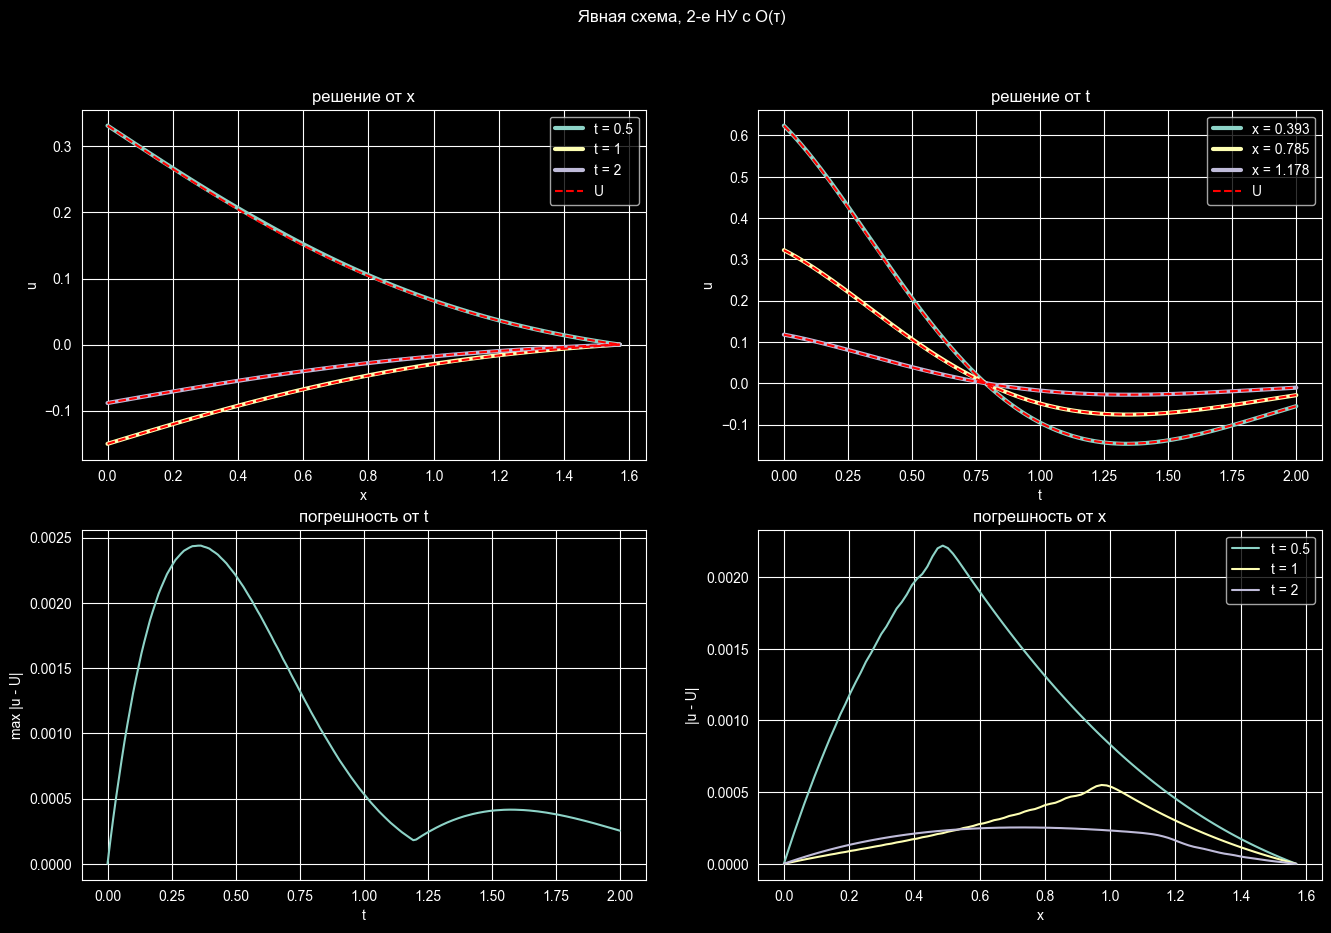

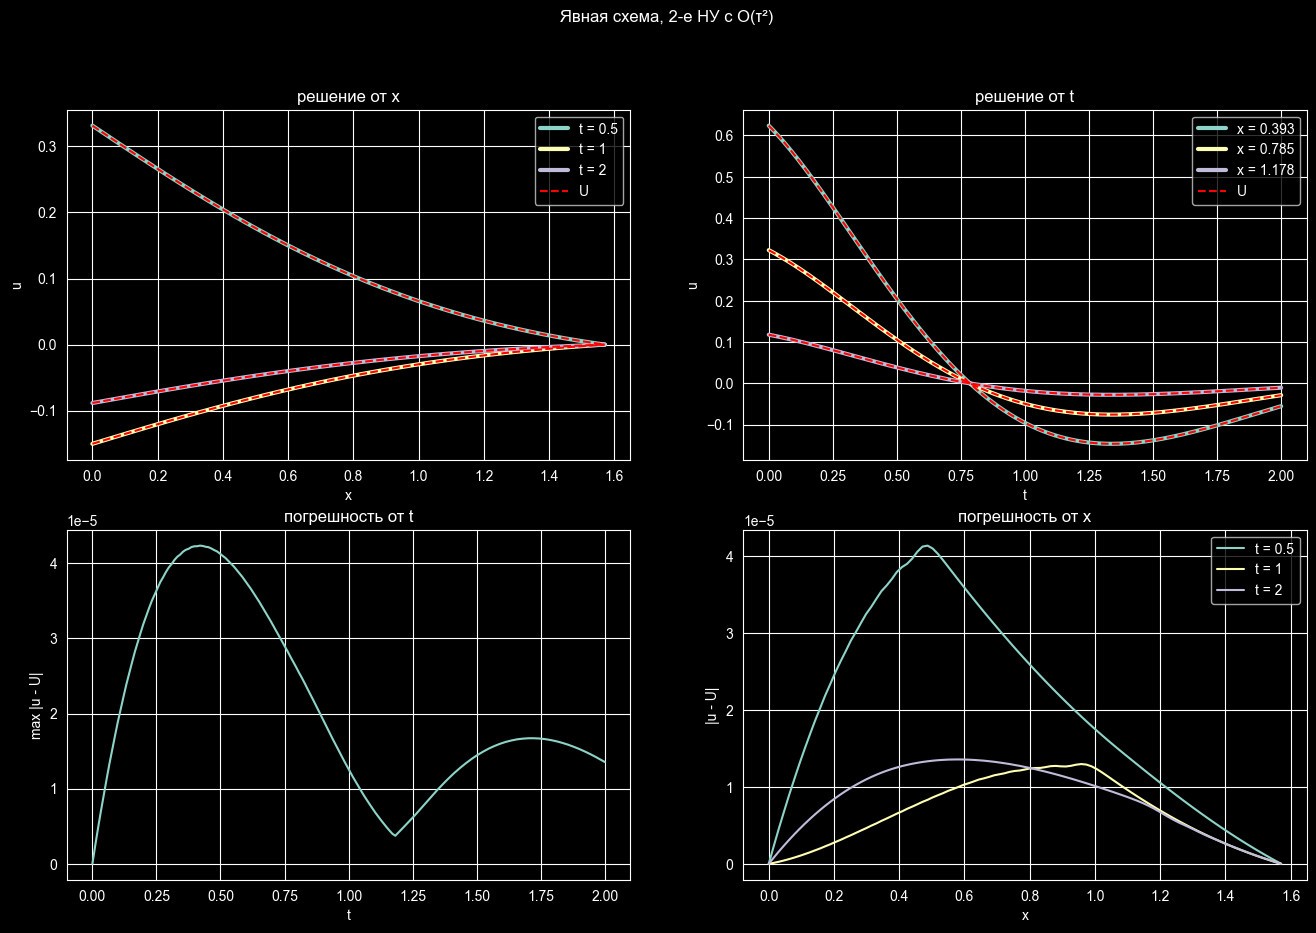

In [14]:
plot_results(by_initial(explicit_results), 'Явная схема')

In [15]:
error_table(explicit_results)

t = 0.25   t = 0.5     t = 1   t = 1.5  \
начальное условие граничные условия                                           
O(τ)              2 точки, O(h)      0.002295  0.002220  0.000550  0.000408   
                  3 точки, O(h²)     0.002295  0.002220  0.000550  0.000408   
                  2 точки, O(h²)     0.002295  0.002220  0.000550  0.000408   
O(τ²)             2 точки, O(h)      0.000037  0.000041  0.000013  0.000014   
                  3 точки, O(h²)     0.000037  0.000041  0.000013  0.000014   
                  2 точки, O(h²)     0.000037  0.000041  0.000013  0.000014   

                                        t = 2  
начальное условие граничные условия            
O(τ)              2 точки, O(h)      0.000254  
                  3 точки, O(h²)     0.000254  
                  2 точки, O(h²)     0.000254  
O(τ²)             2 точки, O(h)      0.000014  
                  3 точки, O(h²)     0.000014  
                  2 точки, O(h²)     0.000014

### Зависимость погрешности от $h$

Уменьшаем $h$ вдвое при фиксированном $\sigma$, то есть $\tau$ тоже уменьшается вдвое (явная схема остаётся устойчивой). Число шагов $K_0$ подбираем для $\sigma = 0.5$ на самой грубой сетке $N = 10$ и дальше удваиваем вместе с $N$; из-за округления $K_0$ вверх на всех сетках $\sigma \approx 0.45$. Для каждой сетки считаем погрешность на всём отрезке времени $\varepsilon = \max_{k, j} |u_j^k - U(x_j, t^k)|$ и порядок $p = \log_2(\varepsilon_h / \varepsilon_{h/2})$. По теореме из раздела 5.4 устойчивая схема с порядком аппроксимации $p$ сходится с тем же порядком, $\varepsilon \approx Ch^p$, откуда $\varepsilon_h / \varepsilon_{h/2} = 2^p$.

Поскольку $\tau \sim h$, порядок по $h$ здесь совпадает с общим порядком схемы: ожидаем $p = 2$ при аппроксимации начального условия со вторым порядком и $p = 1$ - с первым.

In [16]:
def convergence_study(scheme, variants, grids, cond=dirichlet):
    rows = []

    for name, (initial, boundary) in variants.items():
        errors = [error(*scheme(initial, boundary, n, k, cond)).max() for n, k in grids]

        for i, (n, k) in enumerate(grids):
            rows.append({
                'вариант': name,
                'h': l / n,
                'tau': T / k,
                'погрешность': errors[i],
                'порядок': np.log2(errors[i - 1] / errors[i]) if i > 0 else np.nan,
            })

    return pd.DataFrame(rows)


def study_table(study, step):
    return study.pivot_table(index='вариант', columns=step, values=['погрешность', 'порядок'], sort=False)


def plot_convergence(study, step, title):
    plt.figure(figsize=(8, 5))
    ax = sns.lineplot(data=study, x=step, y='погрешность', hue='вариант', marker='o')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)


initial_variants = {
    f'2-е НУ с {initial_name}': (initial, boundary_two_point_first_order)
    for initial_name, initial in initials.items()
}

N_list = [10, 20, 40, 80, 160]
K_0 = steps_for_sigma(N_list[0], sigma)
sigma_grids = [(n, K_0 * n // N_list[0]) for n in N_list]

explicit_h_study = convergence_study(explicit_scheme, initial_variants, sigma_grids)
study_table(explicit_h_study, 'h')

погрешность                                           порядок  \
h                 0.157080  0.078540  0.039270  0.019635  0.009817  0.078540   
вариант                                                                        
2-е НУ с O(τ)     0.020929  0.010971  0.005679  0.002894  0.001462  0.931846   
2-е НУ с O(τ²)    0.003609  0.000944  0.000238  0.000060  0.000015  1.934452   

                                              
h               0.039270  0.019635  0.009817  
вариант                                       
2-е НУ с O(τ)   0.949985  0.972527  0.985615  
2-е НУ с O(τ²)  1.989609  1.988551  1.994471

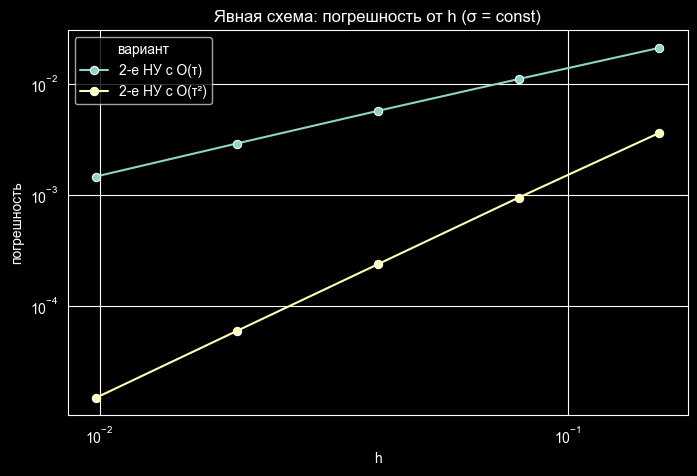

In [17]:
plot_convergence(explicit_h_study, 'h', 'Явная схема: погрешность от h (σ = const)')

### Зависимость погрешности от $\tau$

Фиксируем $N = 40$ и уменьшаем $\tau$ вдвое. Из-за условия $\sigma < 1$ шаг по времени нельзя взять больше $h$, поэтому начинаем с $K = 60$ ($\sigma \approx 0.71$).

Погрешность складывается из пространственной $C_1h^2$ и временной: $C_2\tau^2$ при втором порядке начального условия и $C_2\tau$ при первом.

In [18]:
N_tau = 40
K_list = [60, 120, 240, 480, 960]

explicit_tau_study = convergence_study(explicit_scheme, initial_variants, [(N_tau, k) for k in K_list])
study_table(explicit_tau_study, 'tau')

погрешность                                           порядок  \
tau               0.033333  0.016667  0.008333  0.004167  0.002083  0.016667   
вариант                                                                        
2-е НУ с O(τ)     0.007217  0.003602  0.001809  0.000908  0.000456  1.002344   
2-е НУ с O(τ²)    0.000385  0.000094  0.000029  0.000020  0.000018  2.029758   

                                              
tau             0.008333  0.004167  0.002083  
вариант                                       
2-е НУ с O(τ)   0.993815  0.994485  0.992733  
2-е НУ с O(τ²)  1.720389  0.541070  0.146271

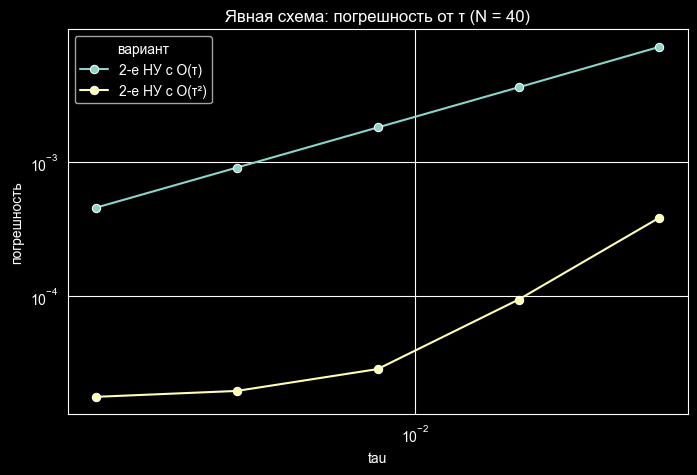

In [19]:
plot_convergence(explicit_tau_study, 'tau', f'Явная схема: погрешность от τ (N = {N_tau})')

При аппроксимации начального условия с первым порядком погрешность во всём диапазоне убывает как $O(\tau)$ (порядок 0.99–1.00): временная составляющая $C_2\tau$ здесь всё время больше пространственной.

При втором порядке погрешность сначала убывает как $O(\tau^2)$: при первых двух уменьшениях шага она падает в 4.1 и 3.3 раза (порядок 2.03 и 1.72), хотя уже на первой сетке $\tau < h$. Только на двух последних шагах она выходит на плато $\approx 1.8 \cdot 10^{-5}$ - пространственную составляющую $C_1h^2$ при $N = 40$. Значит, условие $\tau < h$ само по себе не означает, что временная составляющая меньше пространственной: это зависит ещё и от констант $C_1$ и $C_2$.

### Устойчивость явной схемы

Проверим условие устойчивости $\sigma < 1$: посчитаем погрешность $\max_{k, j}|u_j^k - U(x_j, t^k)|$ при $N = 100$ для нескольких $\sigma$ (фактическое $\sigma$ немного меньше заданного из-за округления $K$ вверх).

In [20]:
N_stability = 100
sigma_list = [0.25, 0.5, 0.9, 1.0, 1.05, 1.2]

stability_rows = {}
for s in sigma_list:
    K_s = steps_for_sigma(N_stability, s)
    sigma_actual = (a * T / K_s / (l / N_stability)) ** 2
    stability_rows[round(sigma_actual, 4)] = {
        f'2-е НУ с {initial_name}': error(*explicit_scheme(initial, boundary_two_point_first_order, N_stability, K_s)).max()
        for initial_name, initial in initials.items()
    }

stability_table = pd.DataFrame(stability_rows).T.rename_axis('σ')
stability_table

,2-е НУ с O(τ),2-е НУ с O(τ²)
σ,,
0.2493,1.730607e-03,2.116564e-05
0.4948,2.438625e-03,4.236474e-05
0.8895,3.277706e-03,7.674641e-05
0.9895,3.483783e-03,8.551602e-05
1.0375,1.688864e+13,3.326787e+11
1.1843,5.564028e+34,1.174540e+33


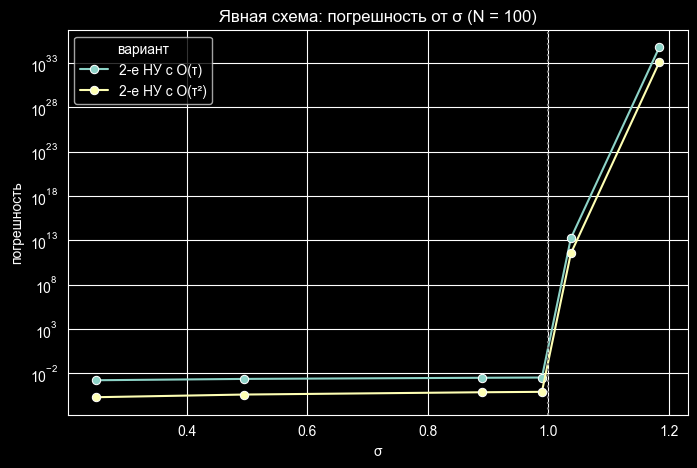

In [21]:
plt.figure(figsize=(8, 5))
ax = sns.lineplot(
    data=stability_table.reset_index().melt(id_vars='σ', var_name='вариант', value_name='погрешность'),
    x='σ', y='погрешность', hue='вариант', marker='o',
)
ax.axvline(1, color='gray', linestyle=':')
ax.set_yscale('log')
ax.set_title(f'Явная схема: погрешность от σ (N = {N_stability})');

При $\sigma \le 0.99$ погрешность остаётся малой; она растёт с $\sigma$, потому что при фиксированном $h$ больший $\sigma$ означает больший шаг $\tau$. При $\sigma \approx 1.04$ и $\sigma \approx 1.18$ решение разрушается: погрешность вырастает до $10^{11}$–$10^{34}$. Это согласуется с условием $\sigma < 1$ из методички, но точную границу устойчивости для нашего уравнения (с младшими членами) по этим точкам установить нельзя - утверждаем только то, что проверено опытом.

# 2. Неявная схема

## Внутренние узлы

Если пространственные производные аппроксимировать на **верхнем** временном слое, а производные по времени - так же, как в явной схеме, получим неявную схему:

$
\dfrac{u_j^{k+1} - 2u_j^k + u_j^{k-1}}{\tau^2} + \mu\dfrac{u_j^{k+1} - u_j^{k-1}}{2\tau} = a^2\dfrac{u_{j+1}^{k+1} - 2u_j^{k+1} + u_{j-1}^{k+1}}{h^2} + b\dfrac{u_{j+1}^{k+1} - u_{j-1}^{k+1}}{2h} + cu_j^{k+1} + f_j^{k+1} + O(\tau + h^2), \qquad j = \overline{1, N-1}.
$

Каждое уравнение содержит три неизвестных. Умножив на $\tau^2$ и перенеся известные значения вправо, получаем СЛАУ с трёхдиагональной матрицей:

$
a_j u_{j-1}^{k+1} + b_j u_j^{k+1} + c_j u_{j+1}^{k+1} = d_j,
$

$
a_j = \sigma - b\dfrac{\tau^2}{2h}, \quad b_j = -\left(1 + \dfrac{\mu\tau}{2} + 2\sigma - c\tau^2\right), \quad c_j = \sigma + b\dfrac{\tau^2}{2h}, \quad
d_j = -2u_j^k + \left(1 - \dfrac{\mu\tau}{2}\right)u_j^{k-1} - \tau^2 f_j^{k+1}, \qquad \sigma = \dfrac{a^2\tau^2}{h^2}.
$

Неявная схема абсолютно устойчива, но имеет лишь первый порядок по времени: $O(\tau + h^2)$.

## Метод прогонки

СЛАУ $a_j u_{j-1} + b_j u_j + c_j u_{j+1} = d_j$, $j = \overline{0, N}$ ($a_0 = 0$, $c_N = 0$) решаем методом прогонки:

$
A_j = -\dfrac{c_j}{b_j + a_jA_{j-1}}, \qquad B_j = \dfrac{d_j - a_jB_{j-1}}{b_j + a_jA_{j-1}}, \qquad A_0 = -\dfrac{c_0}{b_0}, \quad B_0 = \dfrac{d_0}{b_0}, \qquad j = \overline{0, N},
$

$
u_j = A_ju_{j+1} + B_j, \quad j = N, N - 1, \ldots, 0 \qquad (u_N = B_N).
$

Коэффициенты системы хранятся построчно в матрице размера $(N + 1) \times 3$ со столбцами $a_j$, $b_j$, $c_j$.

In [22]:
def tridiagonal_solve(slau, d):
    n = len(d)
    A, B = np.zeros(n), np.zeros(n)

    A[0] = -slau[0, 2] / slau[0, 1]
    B[0] = d[0] / slau[0, 1]

    for j in range(1, n):
        a_j, b_j, c_j = slau[j]
        A[j] = -c_j / (b_j + a_j * A[j - 1])
        B[j] = (d[j] - a_j * B[j - 1]) / (b_j + a_j * A[j - 1])

    u = np.zeros(n)
    u[-1] = B[-1]

    for j in range(n - 2, -1, -1):
        u[j] = A[j] * u[j + 1] + B[j]

    return u

## Граничные узлы

В неявной схеме граничные значения нельзя найти после внутренних - уравнения граничных условий становятся **первой и последней строками СЛАУ**. Коэффициенты берём из тех же функций, что и для явной схемы.

Двухточечные аппроксимации дают по два неизвестных и сразу ставятся в трёхдиагональную матрицу. Трёхточечная аппроксимация даёт три неизвестных, и матрица перестаёт быть трёхдиагональной. Исключим лишнее неизвестное линейной комбинацией с соседним уравнением: вычтем из первого уравнения уравнение $j = 1$ ($a_1u_0 + b_1u_1 + c_1u_2 = d_1$), умноженное на $q_0 = e_0 / c_1$:

$
(b_0 - q_0 a_1)\,u_0^{k+1} + (c_0 - q_0 b_1)\,u_1^{k+1} = d_0 - q_0 d_1.
$

Аналогично для последнего уравнения и уравнения $j = N-1$ с $q_N = e_N / a_{N-1}$:

$
(a_N - q_N b_{N-1})\,u_{N-1}^{k+1} + (b_N - q_N c_{N-1})\,u_N^{k+1} = d_N - q_N d_{N-1}.
$

Для двухточечных аппроксимаций $e_0 = e_N = 0$, и эти формулы ничего не меняют.

In [23]:
def set_boundary_rows(A, d, rows):
    (b_0, c_0, e_0, d_0), (e_N, a_N, b_N, d_N) = rows

    # исключаем u_2 с помощью уравнения j = 1
    q_0 = e_0 / A[1, 2]
    A[0, 1], A[0, 2], d[0] = b_0 - q_0 * A[1, 0], c_0 - q_0 * A[1, 1], d_0 - q_0 * d[1]

    # исключаем u_{N-2} с помощью уравнения j = N - 1
    q_N = e_N / A[-2, 0]
    A[-1, 0], A[-1, 1], d[-1] = a_N - q_N * A[-2, 1], b_N - q_N * A[-2, 2], d_N - q_N * d[-2]

## Алгоритм неявной схемы

Слои $u^0$, $u^1$ - из начальных условий, как в явной схеме. На каждом шаге по времени заполняем строки СЛАУ для внутренних узлов, дописываем граничные строки и решаем систему прогонкой.

In [24]:
def implicit_scheme(initial, boundary, N, K, cond=dirichlet):
    x, t, h, tau = make_grid(N, K)
    sigma = a * a * tau * tau / (h * h)

    u = np.zeros((K + 1, N + 1), dtype=np.float64)
    u[0] = psi_1(x)
    u[1] = initial(x, tau)
    set_first_layer_boundary(u[1], t[1], cond)

    for k in range(1, K):
        A = np.zeros((N + 1, 3), dtype=np.float64)
        d = np.zeros(N + 1, dtype=np.float64)

        A[1:-1, 0] = sigma - b * tau * tau / (2 * h)
        A[1:-1, 1] = -(1 + mu * tau / 2 + 2 * sigma - c * tau * tau)
        A[1:-1, 2] = sigma + b * tau * tau / (2 * h)
        d[1:-1] = -2 * u[k, 1:-1] + (1 - mu * tau / 2) * u[k - 1, 1:-1] - tau * tau * f(x[1:-1], t[k + 1])

        set_boundary_rows(A, d, boundary(cond, TimeStep(t[k + 1], h, tau, u[k], u[k - 1])))

        u[k + 1] = tridiagonal_solve(A, d)

    return x, t, u

## Результаты неявной схемы

На той же сетке, что и для явной схемы:

In [25]:
implicit_results = run_all(implicit_scheme, N, K)

boundaries_coincide(implicit_results)

True

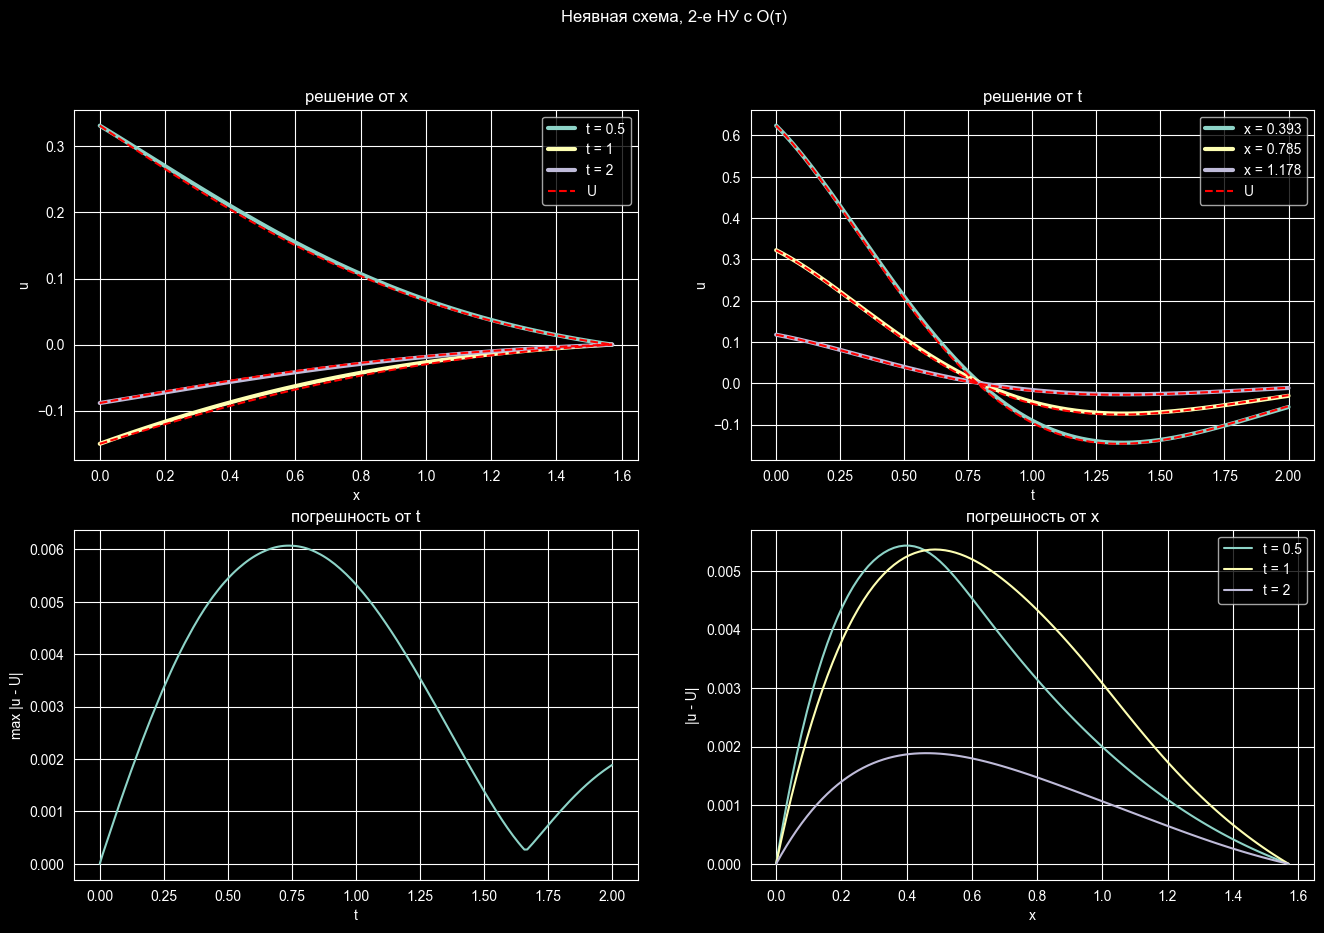

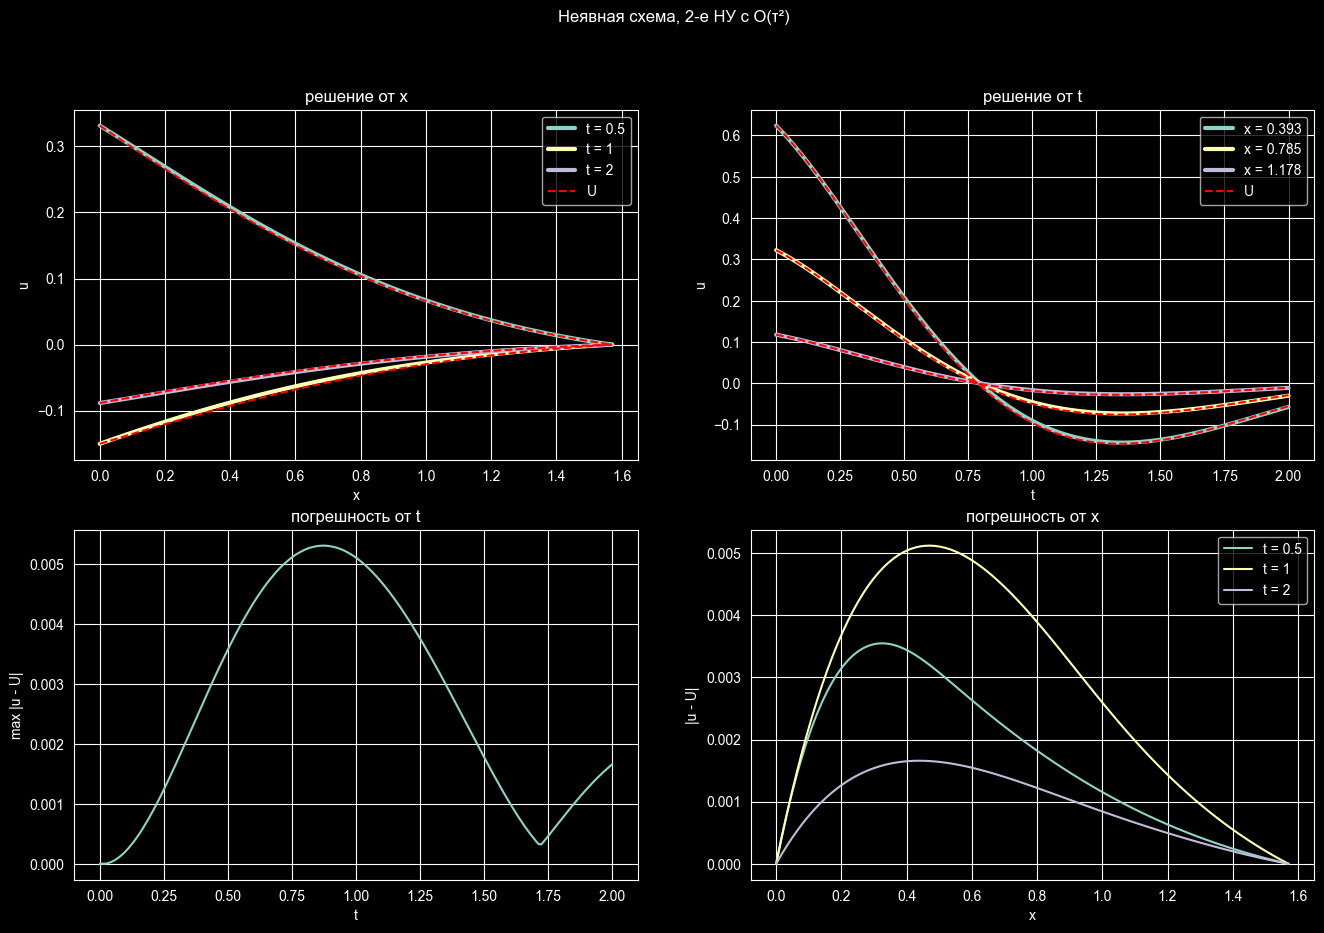

In [26]:
plot_results(by_initial(implicit_results), 'Неявная схема')

In [27]:
error_table(implicit_results)

t = 0.25   t = 0.5     t = 1   t = 1.5  \
начальное условие граничные условия                                           
O(τ)              2 точки, O(h)      0.003412  0.005428  0.005362  0.001365   
                  3 точки, O(h²)     0.003412  0.005428  0.005362  0.001365   
                  2 точки, O(h²)     0.003412  0.005428  0.005362  0.001365   
O(τ²)             2 точки, O(h)      0.001273  0.003549  0.005122  0.001758   
                  3 точки, O(h²)     0.001273  0.003549  0.005122  0.001758   
                  2 точки, O(h²)     0.001273  0.003549  0.005122  0.001758   

                                        t = 2  
начальное условие граничные условия            
O(τ)              2 точки, O(h)      0.001888  
                  3 точки, O(h²)     0.001888  
                  2 точки, O(h²)     0.001888  
O(τ²)             2 точки, O(h)      0.001659  
                  3 точки, O(h²)     0.001659  
                  2 точки, O(h²)     0.001659

### Зависимость погрешности от $h$

На тех же сетках, что и для явной схемы ($\sigma = \text{const}$, $\tau \sim h$). Здесь главным будет член $O(\tau)$, и порядок окажется первым независимо от аппроксимации начального условия.

In [28]:
implicit_h_study = convergence_study(implicit_scheme, initial_variants, sigma_grids)
study_table(implicit_h_study, 'h')

погрешность                                           порядок  \
h                 0.157080  0.078540  0.039270  0.019635  0.009817  0.078540   
вариант                                                                        
2-е НУ с O(τ)     0.049281  0.026900  0.014099  0.007206  0.003643  0.873455   
2-е НУ с O(τ²)    0.041371  0.023151  0.012254  0.006290  0.003187  0.837512   

                                              
h               0.039270  0.019635  0.009817  
вариант                                       
2-е НУ с O(τ)   0.931974  0.968306  0.984158  
2-е НУ с O(τ²)  0.917844  0.962065  0.980934

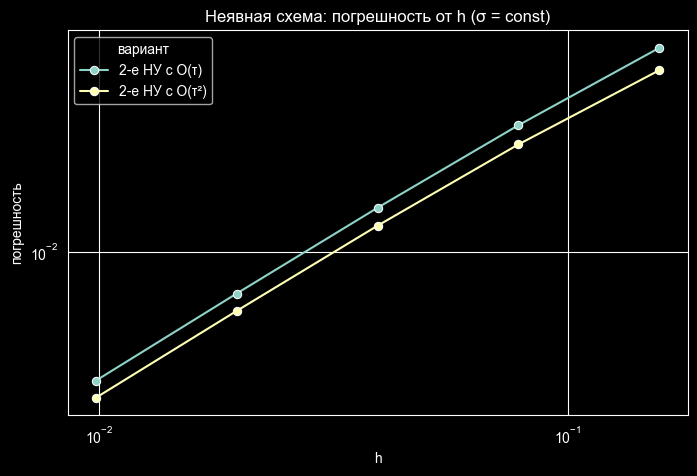

In [29]:
plot_convergence(implicit_h_study, 'h', 'Неявная схема: погрешность от h (σ = const)')

Чтобы увидеть порядок по $h$, нужно, чтобы член $O(\tau)$ убывал так же быстро, как $O(h^2)$. Для этого при уменьшении $h$ вдвое уменьшаем $\tau$ вчетверо ($\tau \sim h^2$). Неявная схема устойчива при любом $\sigma$, поэтому такое возможно (для явной схемы при этом $\sigma \to 0$, что тоже допустимо, но неэкономно).

In [30]:
h2_grids = [(n, K_0 * (n // N_list[0]) ** 2) for n in N_list]

implicit_h2_study = convergence_study(implicit_scheme, initial_variants, h2_grids)
study_table(implicit_h2_study, 'h')

погрешность                                           порядок  \
h                 0.157080  0.078540  0.039270  0.019635  0.009817  0.078540   
вариант                                                                        
2-е НУ с O(τ)     0.049281  0.014071  0.003638  0.000917  0.000230  1.808345   
2-е НУ с O(τ²)    0.041371  0.012195  0.003180  0.000802  0.000201  1.762363   

                                              
h               0.039270  0.019635  0.009817  
вариант                                       
2-е НУ с O(τ)   1.951536  1.987943  1.997095  
2-е НУ с O(τ²)  1.939309  1.986515  1.996268

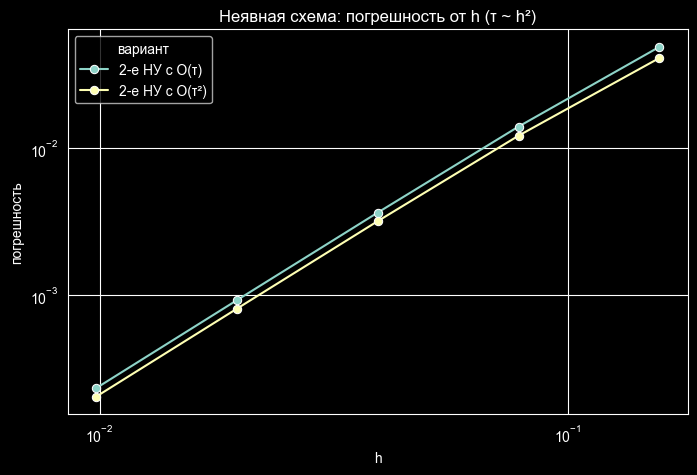

In [31]:
plot_convergence(implicit_h2_study, 'h', 'Неявная схема: погрешность от h (τ ~ h²)')

### Зависимость погрешности от $\tau$

Неявная схема абсолютно устойчива, поэтому $\tau$ можно менять независимо от $h$, в том числе брать $\tau \gg h$. Фиксируем мелкую сетку по пространству $N = 400$ (пространственная погрешность $\sim h^2 \approx 1.5 \cdot 10^{-5}$) и уменьшаем $\tau$ вдвое, начиная с $K = 10$ ($\tau = 0.2$, $\sigma \approx 2600$).

In [32]:
N_tau_implicit = 400
K_list_implicit = [10, 20, 40, 80, 160, 320]

implicit_tau_study = convergence_study(implicit_scheme, initial_variants, [(N_tau_implicit, k) for k in K_list_implicit])
study_table(implicit_tau_study, 'tau')

погрешность                                                    \
tau                0.20000   0.10000   0.05000   0.02500   0.01250   0.00625   
вариант                                                                        
2-е НУ с O(τ)     0.082851  0.047543  0.025769  0.013428  0.006855  0.003463   
2-е НУ с O(τ²)    0.064327  0.040058  0.022211  0.011678  0.005986  0.003030   

                 порядок                                          
tau              0.10000   0.05000   0.02500   0.01250   0.00625  
вариант                                                           
2-е НУ с O(τ)   0.801280  0.883597  0.940417  0.970032  0.985079  
2-е НУ с O(τ²)  0.683315  0.850821  0.927449  0.964197  0.982254

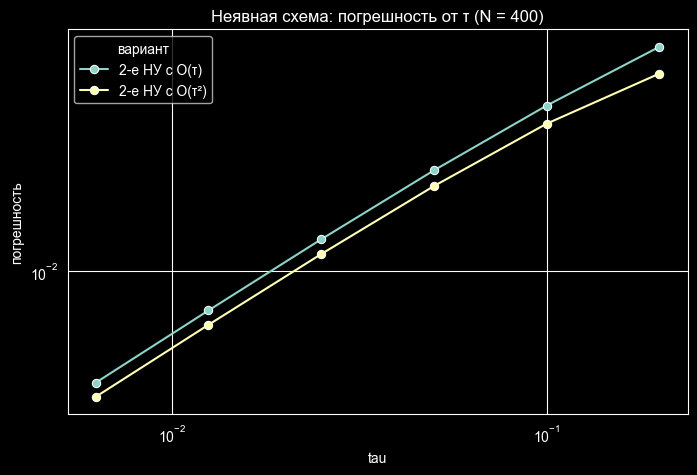

In [33]:
plot_convergence(implicit_tau_study, 'tau', f'Неявная схема: погрешность от τ (N = {N_tau_implicit})')

Даже при $\sigma \gg 1$ неявная схема остаётся устойчивой, а погрешность убывает с первым порядком по $\tau$. Порядок аппроксимации второго начального условия здесь почти не влияет: обе составляющие имеют порядок $O(\tau)$.

# 3. Сравнение схем

Погрешность относительно $U$ в различные моменты времени на одной сетке ($N = 100$, $\sigma = 0.5$). Аппроксимации граничных условий в варианте 7 совпадают, поэтому приводим их по одной:

In [34]:
pd.concat(
    {
        'Явная': error_table(by_initial(explicit_results), ['начальное условие']),
        'Неявная': error_table(by_initial(implicit_results), ['начальное условие']),
    },
    names=['схема'],
)

t = 0.25   t = 0.5     t = 1   t = 1.5     t = 2
схема   начальное условие                                                  
Явная   2-е НУ с O(τ)      0.002295  0.002220  0.000550  0.000408  0.000254
        2-е НУ с O(τ²)     0.000037  0.000041  0.000013  0.000014  0.000014
Неявная 2-е НУ с O(τ)      0.003412  0.005428  0.005362  0.001365  0.001888
        2-е НУ с O(τ²)     0.001273  0.003549  0.005122  0.001758  0.001659

Наблюдаемые порядки на самых мелких сетках:

In [35]:
def last_order(study):
    return study.groupby('вариант', sort=False)['порядок'].last()


pd.DataFrame({
    ('σ = const', 'Явная'): last_order(explicit_h_study),
    ('σ = const', 'Неявная'): last_order(implicit_h_study),
    ('τ ~ h²', 'Неявная'): last_order(implicit_h2_study),
    ('по τ, h = const', 'Неявная'): last_order(implicit_tau_study),
})

σ = const              τ ~ h² по τ, h = const
                   Явная   Неявная   Неявная         Неявная
вариант                                                     
2-е НУ с O(τ)   0.985615  0.984158  1.997095        0.985079
2-е НУ с O(τ²)  1.994471  0.980934  1.996268        0.982254

Погрешность обеих схем на одних и тех же сетках ($\sigma = \text{const}$, то есть $\tau \sim h$):

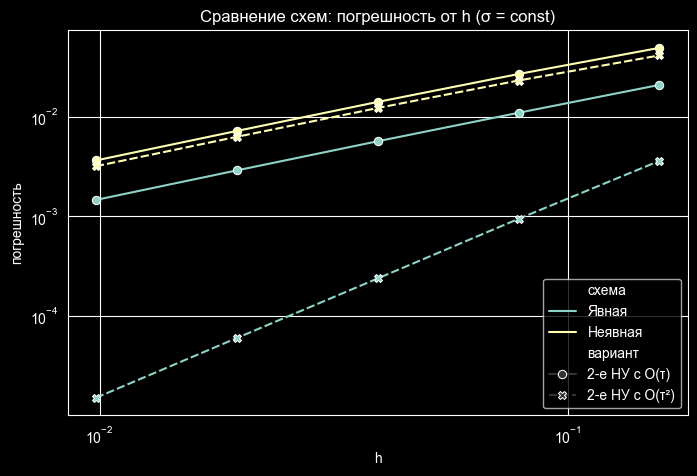

In [36]:
scheme_comparison = pd.concat([
    explicit_h_study.assign(схема='Явная'),
    implicit_h_study.assign(схема='Неявная'),
])

plt.figure(figsize=(8, 5))
ax = sns.lineplot(data=scheme_comparison, x='h', y='погрешность', hue='схема', style='вариант', markers=True)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Сравнение схем: погрешность от h (σ = const)');

Явная схема со вторым порядком начального условия сходится со вторым порядком, а неявная - с первым при обоих начальных условиях. На самой мелкой сетке явная схема точнее неявной в 200 раз ($1.5 \cdot 10^{-5}$ против $3.2 \cdot 10^{-3}$). С первым порядком начального условия обе схемы сходятся с первым порядком, но явная и здесь точнее, в 2.5 раза ($1.5 \cdot 10^{-3}$ против $3.6 \cdot 10^{-3}$).

# 4. Граничные условия с производными

В варианте 7 заданы условия первого рода, на которых три аппроксимации граничных условий неразличимы. Чтобы проверить их реализацию, решим то же уравнение с теми же начальными условиями, но с условиями второго рода, которым удовлетворяет то же аналитическое решение:

$
\dfrac{\partial u}{\partial x}(0, t) = \dfrac{\partial U}{\partial x}(0, t) = -e^{-t}\cos 2t, \qquad
\dfrac{\partial u}{\partial x}\left(\dfrac{\pi}{2}, t\right) = \dfrac{\partial U}{\partial x}\left(\dfrac{\pi}{2}, t\right) = -e^{-t-\pi/2}\cos 2t,
$

то есть $\alpha = \gamma = 1$, $\beta = \delta = 0$. Функции $\varphi_0$, $\varphi_l$ получаем символьным дифференцированием $U$. Второе начальное условие везде аппроксимируем со вторым порядком.

In [37]:
dU_dx = U_sym.diff(xs)
print('phi_0(t) =', sp.simplify(dU_dx.subs(xs, 0)))
print('phi_l(t) =', sp.simplify(dU_dx.subs(xs, sp.pi / 2)))

neumann = Conditions(
    alpha=1, beta=0, phi_0=sp.lambdify(ts, dU_dx.subs(xs, 0), 'numpy'),
    gamma=1, delta=0, phi_l=sp.lambdify(ts, dU_dx.subs(xs, sp.pi / 2), 'numpy'),
)

boundary_variants = {
    boundary_name: (initial_second_order, boundary)
    for boundary_name, boundary in boundaries.items()
}

neumann_results = {
    (scheme_name, boundary_name): scheme(initial, boundary, N, K, neumann)
    for scheme_name, scheme in {'Явная': explicit_scheme, 'Неявная': implicit_scheme}.items()
    for boundary_name, (initial, boundary) in boundary_variants.items()
}

phi_0(t) = -exp(-t)*cos(2*t)
phi_l(t) = -exp(-t - pi/2)*cos(2*t)


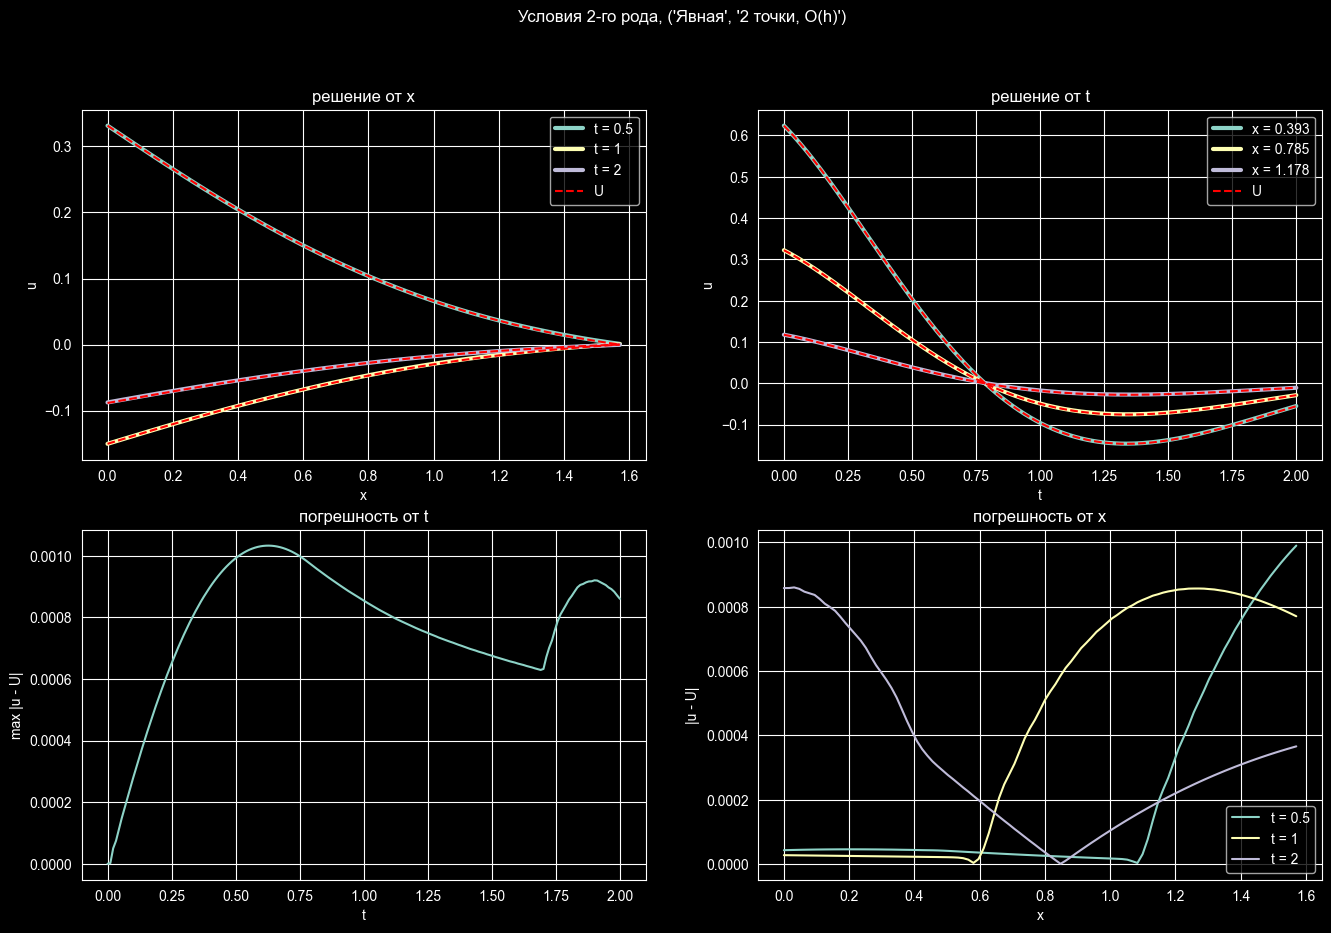

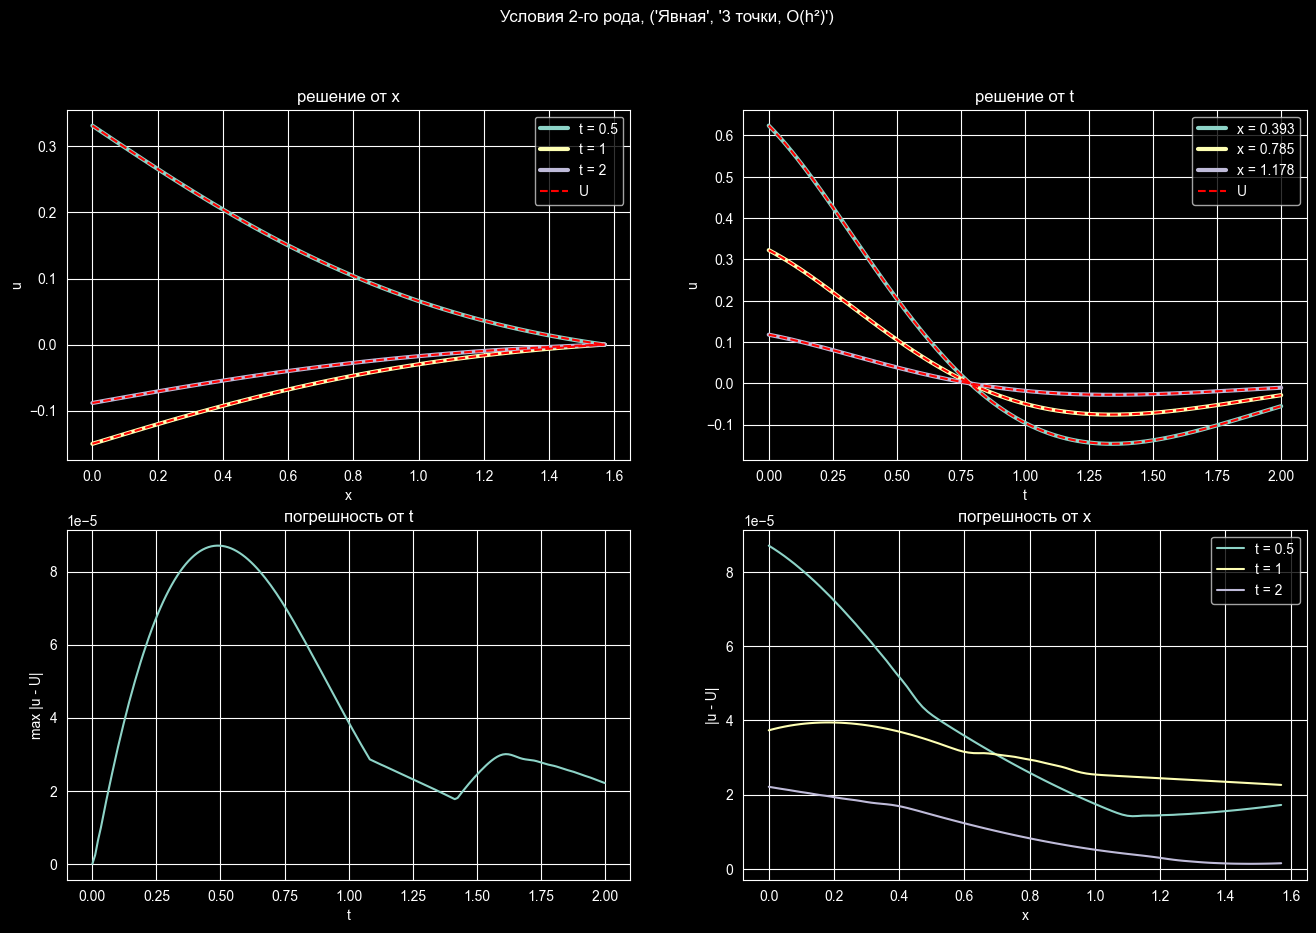

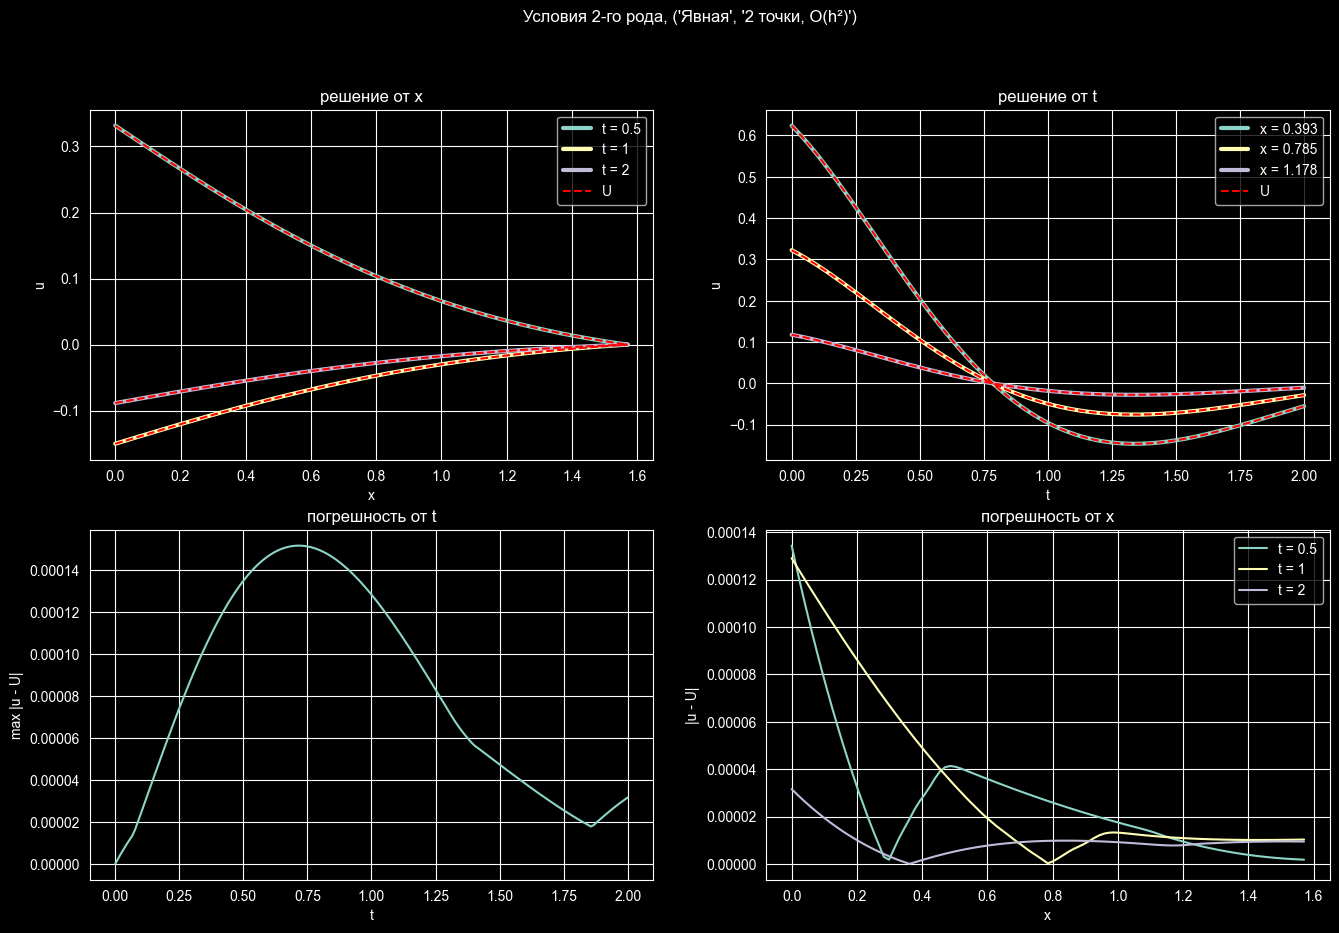

In [38]:
plot_results({key: neumann_results[key] for key in neumann_results if key[0] == 'Явная'}, 'Условия 2-го рода')

In [39]:
error_table(neumann_results, ['схема', 'граничные условия'])

t = 0.25   t = 0.5     t = 1   t = 1.5     t = 2
схема   граничные условия                                                  
Явная   2 точки, O(h)      0.000659  0.000990  0.000857  0.000675  0.000860
        3 точки, O(h²)     0.000068  0.000087  0.000039  0.000025  0.000022
        2 точки, O(h²)     0.000075  0.000134  0.000129  0.000047  0.000032
Неявная 2 точки, O(h)      0.001552  0.004983  0.009616  0.005711  0.001479
        3 точки, O(h²)     0.001527  0.004983  0.009707  0.005669  0.001804
        2 точки, O(h²)     0.001566  0.005030  0.009722  0.005655  0.001802

### Зависимость погрешности от $h$

Явная схема при $\sigma = \text{const}$ имеет порядок $O(\tau^2 + h^2)$, поэтому порядок аппроксимации граничных условий виден напрямую:

In [40]:
neumann_explicit_h_study = convergence_study(explicit_scheme, boundary_variants, sigma_grids, neumann)
study_table(neumann_explicit_h_study, 'h')

погрешность                                           порядок  \
h                 0.157080  0.078540  0.039270  0.019635  0.009817  0.078540   
вариант                                                                        
2 точки, O(h)     0.007737  0.004588  0.002438  0.001282  0.000657  0.754108   
3 точки, O(h²)    0.006995  0.001894  0.000496  0.000127  0.000032  1.884527   
2 точки, O(h²)    0.015504  0.003835  0.000939  0.000231  0.000057  2.015512   

                                              
h               0.039270  0.019635  0.009817  
вариант                                       
2 точки, O(h)   0.912125  0.927183  0.965523  
3 точки, O(h²)  1.934022  1.967697  1.983926  
2 точки, O(h²)  2.029848  2.021393  2.012134

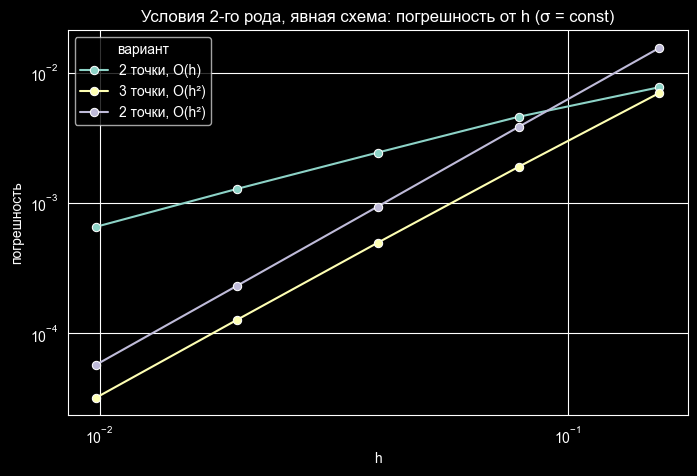

In [41]:
plot_convergence(neumann_explicit_h_study, 'h', 'Условия 2-го рода, явная схема: погрешность от h (σ = const)')

Для неявной схемы берём $\tau \sim h^2$, чтобы член $O(\tau)$ не заслонял пространственную погрешность:

In [42]:
neumann_implicit_h_study = convergence_study(implicit_scheme, boundary_variants, h2_grids, neumann)
study_table(neumann_implicit_h_study, 'h')

погрешность                                           порядок  \
h                 0.157080  0.078540  0.039270  0.019635  0.009817  0.078540   
вариант                                                                        
2 точки, O(h)     0.069053  0.021335  0.005699  0.001621  0.000690  1.694471   
3 точки, O(h²)    0.074358  0.022202  0.005796  0.001465  0.000367  1.743784   
2 точки, O(h²)    0.078468  0.022660  0.005863  0.001478  0.000370  1.791969   

                                              
h               0.039270  0.019635  0.009817  
вариант                                       
2 точки, O(h)   1.904564  1.814112  1.232371  
3 точки, O(h²)  1.937576  1.984493  1.996172  
2 точки, O(h²)  1.950355  1.987718  1.996936

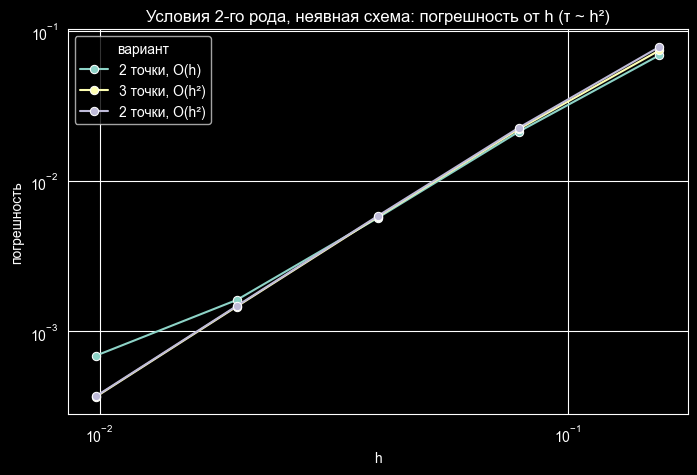

In [43]:
plot_convergence(neumann_implicit_h_study, 'h', 'Условия 2-го рода, неявная схема: погрешность от h (τ ~ h²)')

Для аппроксимаций второго порядка порядок стремится к 2. У двухточечной аппроксимации первого порядка вклад $O(h)$ на грубых сетках заслонён членом $O(\tau)$ схемы и проявляется только на самых мелких сетках, где наблюдаемый порядок начинает падать к единице.

### Зависимость погрешности от $\tau$

При фиксированном $h$ погрешность складывается из временной и пространственной составляющих, а пространственная теперь зависит ещё и от аппроксимации граничных условий. Явная схема - на той же сетке, что в разделе 1 ($N = 40$):

In [44]:
neumann_explicit_tau_study = convergence_study(explicit_scheme, boundary_variants, [(N_tau, k) for k in K_list], neumann)
study_table(neumann_explicit_tau_study, 'tau')

погрешность                                           порядок  \
tau               0.033333  0.016667  0.008333  0.004167  0.002083  0.016667   
вариант                                                                        
2 точки, O(h)     0.002348  0.002554  0.002646  0.002689  0.002710 -0.121759   
3 точки, O(h²)    0.000703  0.000293  0.000195  0.000172  0.000167  1.262701   
2 точки, O(h²)    0.001063  0.000705  0.000436  0.000280  0.000196  0.593144   

                                              
tau             0.008333  0.004167  0.002083  
вариант                                       
2 точки, O(h)  -0.050902 -0.023269 -0.011144  
3 точки, O(h²)  0.588627  0.179261  0.042925  
2 точки, O(h²)  0.692847  0.639995  0.511798

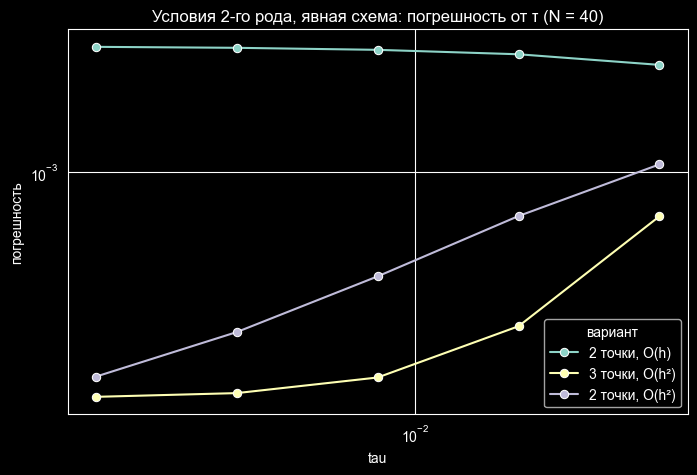

In [45]:
plot_convergence(neumann_explicit_tau_study, 'tau', f'Условия 2-го рода, явная схема: погрешность от τ (N = {N_tau})')

Неявная схема - на мелкой сетке $N = 400$, как в разделе 2:

In [46]:
neumann_implicit_tau_study = convergence_study(implicit_scheme, boundary_variants, [(N_tau_implicit, k) for k in K_list_implicit], neumann)
study_table(neumann_implicit_tau_study, 'tau')

погрешность                                                    \
tau                0.20000   0.10000   0.05000   0.02500   0.01250   0.00625   
вариант                                                                        
2 точки, O(h)     0.116238  0.073330  0.040636  0.021350  0.010939  0.005536   
3 точки, O(h²)    0.116531  0.073518  0.040742  0.021407  0.010968  0.005550   
2 точки, O(h²)    0.116536  0.073521  0.040744  0.021408  0.010969  0.005551   

                 порядок                                          
tau              0.10000   0.05000   0.02500   0.01250   0.00625  
вариант                                                           
2 точки, O(h)   0.664613  0.851629  0.928514  0.964779  0.982672  
3 точки, O(h²)  0.664548  0.851562  0.928454  0.964824  0.982735  
2 точки, O(h²)  0.664547  0.851554  0.928445  0.964788  0.982671

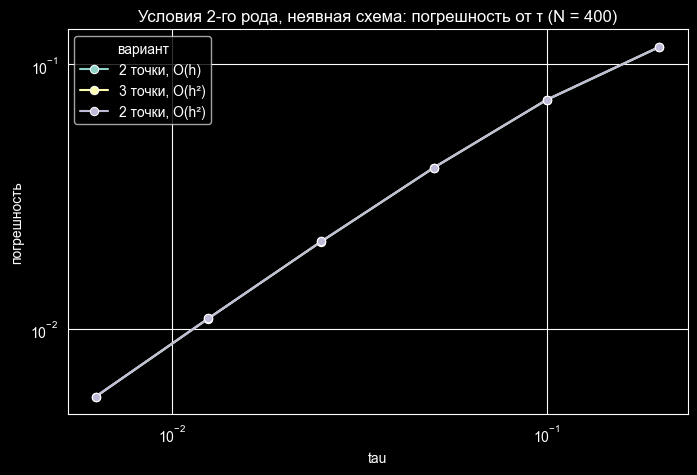

In [47]:
plot_convergence(neumann_implicit_tau_study, 'tau', f'Условия 2-го рода, неявная схема: погрешность от τ (N = {N_tau_implicit})')

У явной схемы при $N = 40$ погрешность почти целиком пространственная, и её поведение зависит от аппроксимации граничных условий:

- у двухточечной аппроксимации первого порядка погрешность около $2.3$–$2.7 \cdot 10^{-3}$ и с уменьшением $\tau$ не убывает (даже немного растёт: при больших $\tau$ временная составляющая, по-видимому, частично компенсирует пространственную $O(h)$);
- у трёхточечной аппроксимации погрешность после двух уменьшений шага выходит на плато $\approx 1.7 \cdot 10^{-4}$;
- у двухточечной аппроксимации второго порядка погрешность продолжает убывать с $\tau$ - с $1.1 \cdot 10^{-3}$ до $2.0 \cdot 10^{-4}$, порядок 0.5–0.7. Это слагаемое $O(h\tau)$ в её погрешности $O(h^2 + h\tau)$, о котором говорилось при выводе.

У неявной схемы при $N = 400$ во всём диапазоне преобладает временная составляющая $O(\tau)$: погрешности трёх вариантов практически совпадают, а порядок растёт к 1 (с 0.66 до 0.98).